# Eleições Presidenciais 2026 — análise do 1º e 2º turnos

Fonte: TSE, *Presidente – Votação por seção eleitoral – 2026*, processado por `src/processar_votacao.py`.

**Como usar:** rode as células em ordem. O notebook detecta sozinho quais turnos existem nos dados.
Quando o TSE publicar o 2º turno, baixe o arquivo de novo, rode o script de processamento e
depois rode este notebook outra vez: as seções do 2º turno passam a ser preenchidas.

Todas as figuras são salvas também em `figuras/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd
import analise as an

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
%matplotlib inline

In [2]:
df = an.carregar()
TURNOS = an.turnos(df)
fin = an.finalistas(df)
A, B = fin["A"], fin["B"]
NOME_A, NOME_B = an.nome_curto(fin["nomes"][A]), an.nome_curto(fin["nomes"][B])

print("Turnos disponíveis:", TURNOS)
print(f"Finalistas: {NOME_A} ({A}) e {NOME_B} ({B})")

Turnos disponíveis: [1]
Finalistas: Flavio Bolsonaro (22) e Lula (13)


## 1. Resultado nacional

In [3]:
resumo = an.resumo_nacional(df)
resumo

,turno,nr,nome,tipo,votos,pct_validos,pct_total
0,1,22,FLAVIO NANTES BOLSONARO,Nominal,56104503,47.03,44.78
1,1,13,LUIZ INÁCIO LULA DA SILVA,Nominal,53879538,45.16,43.01
2,1,96,VOTO NULO,Nulo,3669003,NaN,2.93
3,1,70,AUGUSTO JORGE CURY,Nominal,3448569,2.89,2.75
4,1,14,RENAN ANTONIO FERREIRA DOS SANTOS,Nominal,2675887,2.24,2.14
5,1,55,RONALDO RAMOS CAIADO,Nominal,2605148,2.18,2.08
6,1,95,VOTO BRANCO,Branco,2300798,NaN,1.84
7,1,30,ROMEU ZEMA NETO,Nominal,326488,0.27,0.26
8,1,80,SAMARA MARTINS DA SILVA FEITOSA,Nominal,122911,0.10,0.10
9,1,16,HERTZ DA CONCEICAO DIAS,Nominal,43103,0.04,0.03


In [4]:
# Votos totais (≈ comparecimento), brancos e nulos por turno
an.comparecimento(df)

TP_VOTO,Branco,Nominal,Nulo,total_votos,pct_brancos,pct_nulos
NR_TURNO,,,,,,
1,2300798,119306034,3669003,125275835,1.84,2.93


## 2. Distribuição do voto por região

Barras 100%: o finalista A à esquerda, o B à direita e os demais candidatos no meio.
A linha pontilhada marca 50%.

grupo,validos,Flavio Bolsonaro,Lula,Outros
REGIAO,,,,
Norte,10192323,49.15,44.65,6.20
Nordeste,33705898,30.85,63.77,5.38
Centro-Oeste,9084532,56.51,32.62,10.88
Sudeste,48482385,51.36,39.68,8.96
Sul,17509891,60.08,31.28,8.65
Exterior,331005,43.47,47.55,8.98


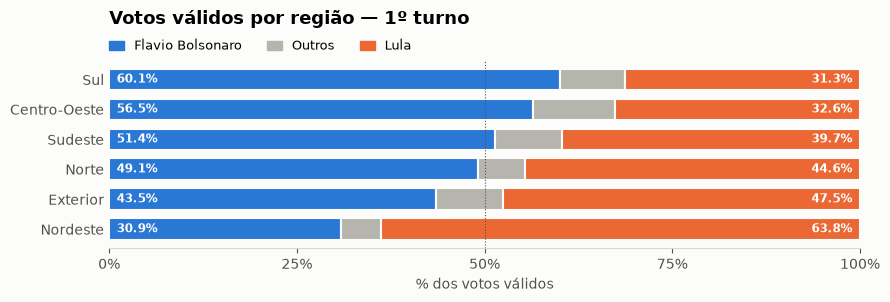

In [5]:
for t in TURNOS:
    tab = an.percentuais(df, t, "REGIAO", fin)
    tab = tab.reindex([r for r in an.ORDEM_REGIOES if r in tab.index])
    an.barras_empilhadas(tab, fin, f"Votos válidos por região — {t}º turno", f"regiao_turno{t}")
    display(tab[["validos", "pct_A", "pct_B", "pct_Outros"]].rename(columns={
        "pct_A": NOME_A, "pct_B": NOME_B, "pct_Outros": "Outros"}))

## 3. Distribuição do voto por UF

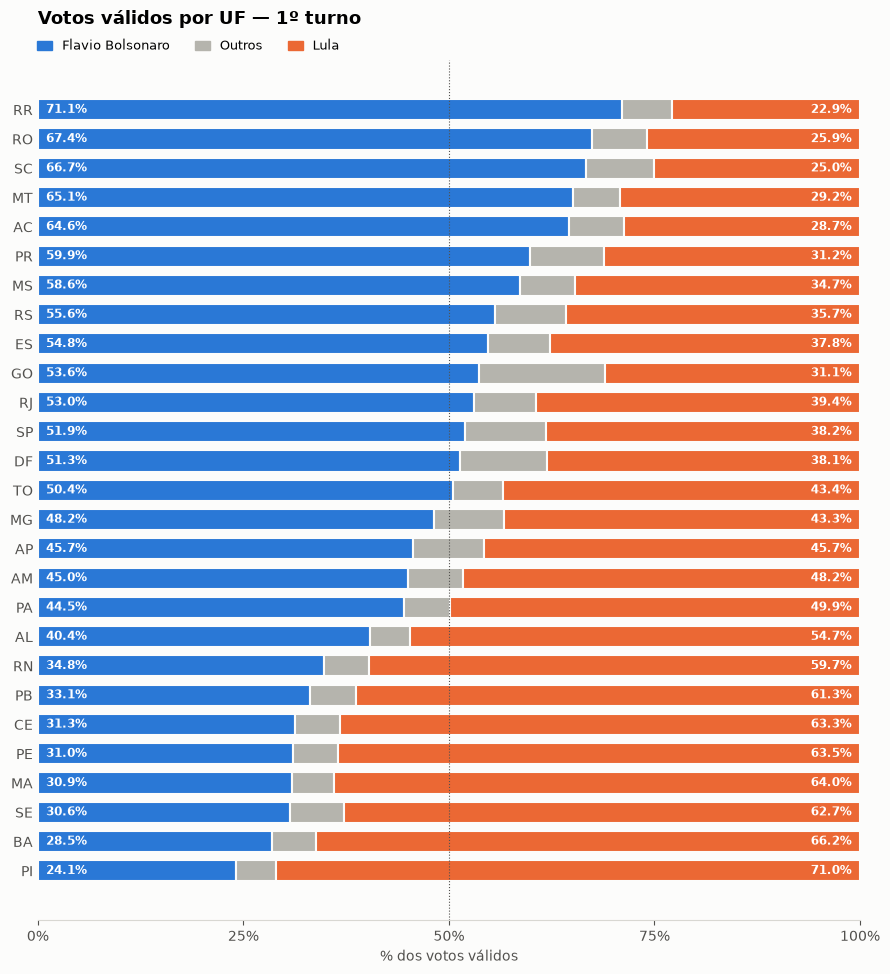

In [6]:
for t in TURNOS:
    tab = an.percentuais(df, t, "SG_UF", fin).drop(["ZZ", "VT"], errors="ignore")
    an.barras_empilhadas(tab, fin, f"Votos válidos por UF — {t}º turno", f"uf_turno{t}")

## 4. Mapa: quem venceu em cada município e por qual margem

Azul = vantagem do finalista A; laranja = vantagem do B. Quanto mais forte a cor, maior a
margem (em pontos percentuais dos votos válidos). Municípios vencidos por outro candidato
aparecem hachurados.

Na primeira execução, a malha municipal do IBGE e a tabela de correspondência de códigos
TSE→IBGE são baixadas para `data/raw/` (precisa de internet só dessa vez).

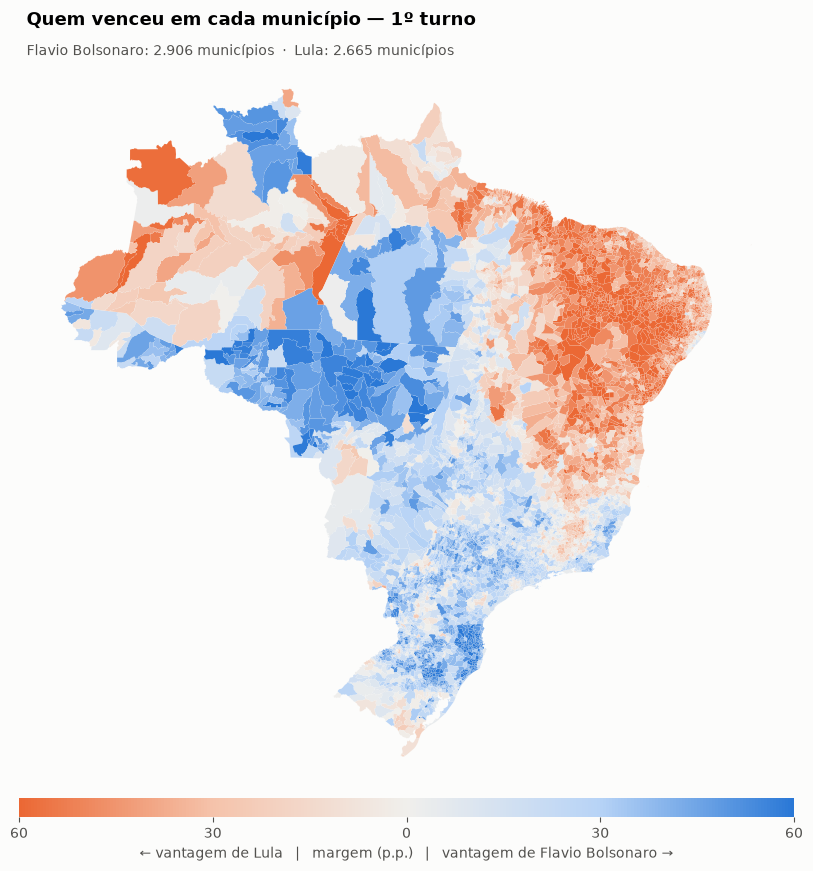

In [7]:
malha = an.carregar_malha()
MUN = {}
for t in TURNOS:
    MUN[t] = an.municipios(df, t, fin)
    an.mapa_margem(MUN[t], malha, fin, t)

In [8]:
# Municípios vencidos por candidato e distribuição das margens
for t in TURNOS:
    m = MUN[t]
    print(f"--- {t}º turno ---")
    display(m.groupby("nome_vencedor").agg(
        municipios=("CD_MUNICIPIO", "count"),
        margem_mediana_pp=("margem_pp", "median"),
        vitorias_acima_de_40pp=("margem_pp", lambda s: (s > 40).sum()),
    ).sort_values("municipios", ascending=False))

--- 1º turno ---


,municipios,margem_mediana_pp,vitorias_acima_de_40pp
nome_vencedor,,,
Flavio Bolsonaro,2906,26.27,662
Lula,2665,38.78,1265


In [9]:
# Disputas mais apertadas entre municípios grandes (>= 50 mil votos válidos)
t = TURNOS[-1]
(MUN[t][MUN[t]["validos"] >= 50_000]
 .nsmallest(15, "margem_pp")
 [["SG_UF", "NM_MUNICIPIO", "validos", "nome_vencedor", "pct_vencedor", "margem_pp"]])

,SG_UF,NM_MUNICIPIO,validos,nome_vencedor,pct_vencedor,margem_pp
1816,MG,ITUIUTABA,55269,Lula,45.76,0.42
3978,RS,BAGÉ,60797,Flavio Bolsonaro,46.02,0.45
2160,MG,TEÓFILO OTONI,73393,Lula,47.45,0.55
2689,PB,JOÃO PESSOA,470987,Lula,46.50,0.84
2600,PB,BAYEUX,59157,Lula,47.18,0.87
4850,SP,ARARAQUARA,125337,Flavio Bolsonaro,45.82,1.00
203,BA,EUNÁPOLIS,61417,Lula,47.18,1.00
2434,PA,ANANINDEUA,283668,Flavio Bolsonaro,46.16,1.19
2041,MG,SABARÁ,71138,Flavio Bolsonaro,45.81,1.60
5109,SP,JANDIRA,56221,Flavio Bolsonaro,45.39,1.73


## 5. Onde se concentraram os votos dos demais candidatos (1º turno)

É o eleitorado disputado no 2º turno. Entram os candidatos não finalistas com pelo menos
1% dos votos válidos. Em destaque, as três UFs em que cada um foi mais forte.

['Augusto Cury', 'Renan Santos', 'Ronaldo Caiado']


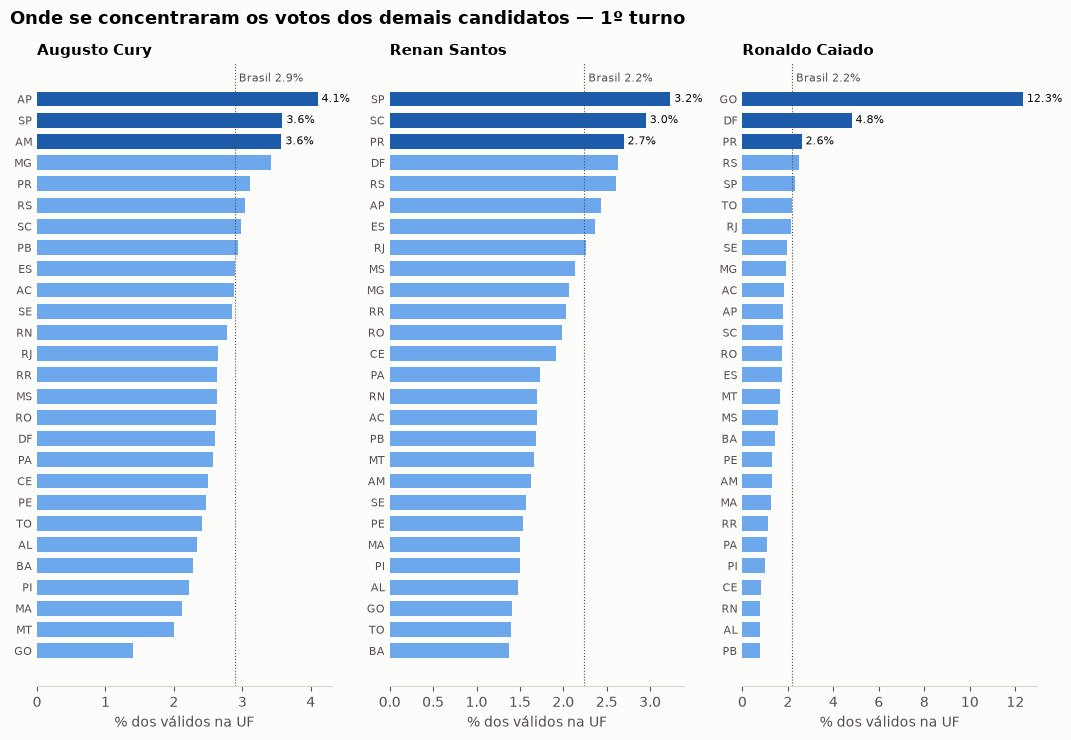

In [10]:
MENORES = an.candidatos_menores(df, fin, minimo_pct=1.0)
print([an.nome_curto(fin["nomes"][n]) for n in MENORES])
an.grafico_menores_uf(df, fin, MENORES);

In [11]:
# Municípios com maior % de cada um (mínimo de 10 mil votos válidos)
for nr in MENORES:
    print(an.nome_curto(fin["nomes"][nr]))
    display(an.top_municipios(df, nr, n=10, min_validos=10_000))

Augusto Cury


,SG_UF,NM_MUNICIPIO,validos,votos,pct
0,SP,COLINA,10306,1784,17.31
1,MG,ITAMARANDIBA,18760,1570,8.37
2,MG,PRATA,15760,1116,7.08
3,MG,CAETÉ,24433,1676,6.86
4,RN,PARELHAS,13645,821,6.02
5,MG,RAPOSOS,10166,590,5.80
6,MG,ITABIRITO,32584,1806,5.54
7,MG,BRUMADINHO,26295,1457,5.54
8,MG,IGARAPÉ,25495,1383,5.42
9,MG,SANTA BÁRBARA,17435,942,5.40


Renan Santos


,SG_UF,NM_MUNICIPIO,validos,votos,pct
0,SP,SÃO CAETANO DO SUL,117520,5168,4.40
1,SP,SANTANA DE PARNAÍBA,82191,3570,4.34
2,SC,BLUMENAU,210798,8687,4.12
3,SP,COTIA,141387,5766,4.08
4,SP,SANTO ANDRÉ,413173,16436,3.98
5,PR,CURITIBA,1093470,43451,3.97
6,SP,SÃO BERNARDO DO CAMPO,460172,18211,3.96
7,SP,JUNDIAÍ,251844,9927,3.94
8,PR,PINHAIS,76424,2998,3.92
9,SP,POÁ,68479,2657,3.88


Ronaldo Caiado


,SG_UF,NM_MUNICIPIO,validos,votos,pct
0,GO,HIDROLÂNDIA,17517,4521,25.81
1,GO,NIQUELÂNDIA,19998,3563,17.82
2,GO,BELA VISTA DE GOIÁS,17872,3167,17.72
3,GO,GUAPÓ,10914,1883,17.25
4,GO,TRINDADE,72156,12022,16.66
5,GO,ABADIA DE GOIÁS,11337,1844,16.27
6,GO,INHUMAS,30646,4969,16.21
7,GO,JARAGUÁ,25426,3909,15.37
8,GO,PIRACANJUBA,13789,2064,14.97
9,GO,LUZIÂNIA,102634,15300,14.91


## 6. Do 1º para o 2º turno

Esta seção só roda quando o arquivo do TSE já tiver o 2º turno.

**Cuidado na leitura:** os dados são agregados por município. Uma associação entre
"muitos votos nos demais candidatos" e "grande ganho do finalista A" mostra um padrão entre
municípios, não prova como cada eleitor votou (falácia ecológica).

In [12]:
if 2 in TURNOS:
    var = an.variacao_uf(df, fin)
    an.grafico_variacao_uf(var, fin)
    display(var.sort_values("ganho_A", ascending=False))
else:
    print("2º turno ainda não está nos dados. Baixe o arquivo do TSE de novo e rode o processamento.")

2º turno ainda não está nos dados. Baixe o arquivo do TSE de novo e rode o processamento.


In [13]:
if 2 in TURNOS:
    fig, transf = an.grafico_transferencia(df, fin)

In [14]:
if 2 in TURNOS:
    # Municípios que mudaram de vencedor entre os turnos
    m1 = MUN[1].set_index("CD_MUNICIPIO")
    m2 = MUN[2].set_index("CD_MUNICIPIO")
    virou = m1.join(m2, lsuffix="_t1", rsuffix="_t2", how="inner")
    virou = virou[virou["vencedor_t1"] != virou["vencedor_t2"]]
    print(f"{len(virou)} municípios mudaram de vencedor")
    display(virou[["SG_UF_t1", "NM_MUNICIPIO_t1", "nome_vencedor_t1", "nome_vencedor_t2",
                   "margem_pp_t2", "validos_t2"]].sort_values("validos_t2", ascending=False).head(20))

## Notas metodológicas
- Percentuais calculados sobre votos válidos (sem brancos e nulos), como no resultado oficial.
- "Votos totais" inclui brancos e nulos e aproxima o comparecimento. A abstenção exige o
  arquivo *Detalhe da apuração por município e zona* do TSE.
- Exterior (`ZZ`) e voto em trânsito (`VT`) entram nos totais nacionais e regionais, mas não no mapa.
- O código de município do TSE difere do IBGE; o mapa usa a tabela de correspondência do
  repositório `betafcc/Municipios-Brasileiros-TSE`.